In [92]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.signal import correlate2d
from Cell2D import Cell2D, draw_array
from matplotlib.colors import LinearSegmentedColormap
from scipy.signal import correlate2d
from empiricaldist import Cdf
from utils import three_frame, number_frame, decorate, set_palette
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from matplotlib.colors import ListedColormap

colors = [
    "white",  # 0 空房：白
    "#D98282",  # 1 A：柔和的红
    "#7EA6CF",  # 2 B：柔和的蓝
    "red",  # 3 AA：深红
    "blue",  # 4 BB：深蓝
    "purple",  # 5 AB：更明显的紫色
]

cmap = ListedColormap(colors)
class Person():

    def __init__(self, loc, group, person_id):
        """Represents a residential agent occupying one grid cell.
        Groups 1 and 2 represent single individuals.
        Groups 3, 4 and 5 represent two-person households.
        """

        # 给每个人一个独立 ID
        # 后面记录组合，和谁呆了一起，就很方便记录
        self.id = person_id

        # 当前住的位置
        self.loc = tuple(loc)

        # 保存这个人的原始 group
        self.group = group

        # 每个人独立随机一个 openness
        # 0.1, 0.2, ..., 0.9
        self.openness = np.random.randint(1, 10) / 10

        # Happiness has not been calculated yet
        self.satisfaction = None
        self.happy = None

        # key = 邻居的 id value = 连续成为邻居的轮数
        self.neighbors = {}

    def get_info(self):
        """Return this person's current information."""

        return {
            "id": self.id,
            "loc": self.loc,
            "group": self.group,
            "openness": self.openness,
            "satisfaction": self.satisfaction,
            "happy": self.happy,
            "neighbors": self.neighbors.copy()
        }
        
    def update_happiness(self, satisfaction, p):
        """
        Update the current residential happiness.
        p: threshold on the fraction of similar neighbors 满意度阈值
        """
        self.satisfaction = float(satisfaction)
        self.happy = bool(self.satisfaction >= p)

    def update_neighbors(self, current_neighbor_ids, advance_round=True):
        """
        current_neighbor_ids: 当前这一轮实际住在周围的人的 ID
        """
        new_neighbors = {}

        for neighbor_id in current_neighbor_ids:
            # 原来就是邻居，保留之前的轮数；新邻居从 0 开始
            rounds = self.neighbors.get(neighbor_id, 0)

            # 正常进入下一轮时，才增加计数
            if advance_round:
                rounds += 1

            new_neighbors[neighbor_id] = rounds

        self.neighbors = new_neighbors
    
def locs_where(condition):
    """Find cells where a logical array is True.

    condition: logical array

    returns: list of location tuples (identified by the row/column indices)
    """
    return list(zip(*np.nonzero(condition)))

class Schelling(Cell2D):
    """Represents a grid of Schelling agents."""

    options = dict(mode='same', boundary='wrap')

    kernel = np.array([[1, 1, 1],
                       [1, 0, 1],
                       [1, 1, 1]], dtype=np.int8)

    def __init__(self, n, p, m = 0.1):
        """Initializes the attributes.

        n: number of rows -- size of the grid
        p: threshold on the fraction of similar neighbors 满意度阈值
        m: marriage
        """
        self.p = p
        # 0 is empty house, 1 is agent labelled red, 2 is agent labelled blue
        choices = np.array([0, 1, 2], dtype=np.int8)
        probs = [0.1, 0.45, 0.45]

        # randomly initialize a grid of houses of n by, occupied by two kinds of agents (red and blue)
        # in roughly equal numbers. About 10% of the houses are empty.
        # in [0, 1, 2], o has 10% to be chosen, 1 and 2 each has 45% to be chosen.
        self.array = np.random.choice(choices, (n, n), p=probs) # 这句已经随机生成了 0 / 1 / 2

        #我得知道上一个代码以及随机生成了0，1，2空房子的不同的group，现在得把每个人信息收集起来
        # Dictionary: key = location, for example (3, 5) value = Person object
        # empty cells will NOT be stored here
        
        # 每创建一个新的 Schelling 模型，Person ID 从 0 开始
        self.next_person_id = 0

        self.people = {} #这里是通过当前位置来找当前这个人
        self.people_by_id = {} #通过id来找到这个人

        # 遍历整个 grid，得到所有的person
        for row in range(n):
            for col in range(n):
                group = self.array[row, col] #一共就只有0，1，2
                # 0 是空房，所以不创建 Person
                if group != 0:
                    loc = (row, col) # 创建这个位置上的 Person
                    person = Person(loc, group, self.next_person_id)
                    self.next_person_id += 1
                    self.people[loc] = person # 保存 Person
                    self.people_by_id[person.id] = person #保存id为xx的人的信息

        # 结婚
        self.m = m
        self.marriage_limit = int(len(self.people) * m)
        self.marriages_done = 0

    def get_person_info(self, person_id):
        """Find a Person by ID and return that person's information."""
        person = self.people_by_id.get(person_id)
        if person is None: return None
        return person.get_info()
    
    def count_neighbors(self):
        """Surveys neighboring cells.

        returns: tuple of
            empty: True where cells are empty
            frac_red: fraction of red neighbors around each cell
            frac_blue: fraction of blue neighbors around each cell
            frac_same: fraction of neighbors with the same color
        """
        a = self.array
        empty = a == 0
        # AA 视为纯 A，BB 视为纯 B，AB 单独统计
        pure_a = (a == 1) | (a == 3)
        pure_b = (a == 2) | (a == 4)
        mixed = a == 5

        # correlate with the kernel, considering the 8 surronding neighbours
        # for agent labelled by red, count how many neighbours are also red agents
        # for agent labelled by blue, count how many neigbours are also blue neighbours
        num_a = correlate2d(pure_a, self.kernel, **self.options)
        num_b = correlate2d(pure_b, self.kernel, **self.options)
        num_ab = correlate2d(mixed, self.kernel, **self.options)
        
        # for each aget, count the total neighbours (no matter blue or red) it has
        num_neighbors = num_a + num_b + num_ab

        # compute fraction of similar neighbors 分别计算red和blue的领居占比
        # Some cells may have no occupied neighbours, so num_neighbors can be 0.
        # Ignore the temporary division warning here.
        with np.errstate(divide='ignore', invalid='ignore'):
            frac_a = num_a / num_neighbors
            frac_b = num_b / num_neighbors
            frac_ab = num_ab / num_neighbors

        # no neighbors is considered the same as no similar neighbors 如果周围领居的数为0，就把red和blue的设为0
        # (this is an arbitrary choice for a rare event)

        frac_a[num_neighbors == 0] = 0
        frac_b[num_neighbors == 0] = 0
        frac_ab[num_neighbors == 0] = 0

        # 用于统计“周围与自己同类型的家庭比例”
        frac_same = np.where(pure_a, frac_a, np.where(pure_b, frac_b, frac_ab))

        # where red is False could be either blue or empty
        # thus, one additional step:
        # for empty cells, frac_same is NaN
        # 如果是空房子，单独设置一下
        frac_same[empty] = np.nan

        # 先复制原来的 frac_same，保持相同的 grid 大小
        satisfaction = frac_same.copy()
        # 每个人使用自己的 openness 计算 satisfaction
        # A：A/AA 和AB各得1分；每个B/BB得person.openness分。
        # B：B/BB 和 AB 各得 1 分；每个A/AA得person.openness分。
        # AA：A/AA 和 AB 各得 1 分；B/BB 得0分。
        # BB：B/BB 和 AB 各得 1 分；A/AA 得0分。
        # AB：每个AB得1分；每个纯A或纯B家庭得person.openness分。
        for loc, person in self.people.items():
            total = num_neighbors[loc]

            if total == 0:
                score = 0

            elif person.group == 1:  # A
                score = (num_a[loc] + num_ab[loc] + person.openness * num_b[loc]) / total

            elif person.group == 2:  # B
                score = (num_b[loc] + num_ab[loc] + person.openness * num_a[loc]) / total

            elif person.group == 3:  # AA
                score = (num_a[loc] + num_ab[loc]) / total

            elif person.group == 4:  # BB
                score = (num_b[loc] + num_ab[loc]) / total

            elif person.group == 5:  # AB
                ab_weight = 1.5
                score = (ab_weight * num_ab[loc] + person.openness * (num_a[loc] + num_b[loc])) / total

            else:
                raise ValueError("Unknown group")

            satisfaction[loc] = score

        return empty, frac_a, frac_b, frac_same, satisfaction

    def segregation(self):
        """Computes the average fraction of similar neighbors.
        returns: fraction of similar neighbors, averaged over cells
        segregation 的含义，如果返回：0.72
        意思：平均而言，每个 agent 的邻居中约 72% 和自己同类型。
        """
        # For quantitative analysis of segregation
        _, _, _, frac_same, _ = self.count_neighbors()
        return np.nanmean(frac_same)

    def update_happiness(self, satisfaction):
        """Update each Person's satisfaction and happy state."""
        #更新每一个人的满足和幸福度

        for loc, person in self.people.items():

            # Satisfaction是当前这个位置的满足程度
            score = satisfaction[loc]
            person.satisfaction = float(score)

            # 更新每一个人的开心程度
            person.happy = bool(score >= self.p)

    def update_neighbors(self, advance_round=True):
        """Update every Person's current neighbors."""

        # 得到当前网络的行数
        rows, cols = self.array.shape

        for person in self.people.values():
            row, col = person.loc

            current_neighbor_ids = set() # 用于保存这个人当前所有邻居的ID

            # 检查周围 8 个位置
            for dr in (-1, 0, 1):
                for dc in (-1, 0, 1):

                    # 不把自己算作邻居
                    if dr == 0 and dc == 0:
                        continue

                    # 是为了实现当前模型使用的boundary='wrap'环形边界
                    neighbor_loc = ((row + dr) % rows, (col + dc) % cols)

                    neighbor = self.people.get(neighbor_loc)

                    if neighbor is not None:
                        current_neighbor_ids.add(neighbor.id)

            person.update_neighbors(current_neighbor_ids, advance_round=advance_round)

    def find_candidates(self, person_id, required_rounds=3):
        """Find possible AA or BB pairs."""
        # 列出person_id能够配对的所有人
        candidates = []

        # 只根据 ID 找到当前这个 Person
        person = self.people_by_id.get(person_id)

        if person is None:
            return candidates

        # 只允许单人参加组合, 
        if person.group != 1 and person.group != 2:
            return candidates

        # 本人必须开心
        if person.happy is not True:
            return candidates
    
        # 检查本人的所有邻居
        for neighbor_id in person.neighbors:

            rounds = person.neighbors[neighbor_id]

            # 连续相邻轮数不足，跳过
            if rounds < required_rounds:
                continue

            # 根据 ID 找到邻居 Person
            neighbor = self.people_by_id.get(neighbor_id)

            # 领居必须存在
            if neighbor is None:
                continue

            # 邻居也必须是单人，
            if neighbor.group != 1 and neighbor.group != 2:
                continue

            # 邻居也必须开心
            if neighbor.happy is not True:
                continue

            candidates.append(neighbor.id)

        return candidates

    def find_all_candidate_pairs(self, required_rounds=3):
        """find_all non-conflicting pairs."""

        # 先收集所有候选人
        possible_pairs = []
        for person_id in self.people_by_id:
            candidates = self.find_candidates(person_id, required_rounds)

            for candidate_id in candidates:
                        # 全模型汇总时，每对只保存一次
                        if person_id < candidate_id:
                            possible_pairs.append((person_id, candidate_id))

        return possible_pairs

    def choose_marriage_pairs(self, possible_pairs):
        # 整个模型还允许结婚多少对
        remaining = self.marriage_limit - self.marriages_done
        if remaining <= 0:
            return []

        # 找出候选组合中涉及的所有人
        candidate_ids = set() #candidate_ids把组合中的ID收集起来，用set是为了去重
        for person_id, partner_id in possible_pairs:
            candidate_ids.add(person_id)
            candidate_ids.add(partner_id)

        # 每个人本轮只抽一次：是否有结婚倾向
        willing_ids = set()
        for person_id in candidate_ids:
            if np.random.random() < self.m: willing_ids.add(person_id)

        # 只留下双方本轮都想结婚的组合
        willing_pairs = []
        for first_id, second_id in possible_pairs:
            if first_id in willing_ids and second_id in willing_ids:
                willing_pairs.append((first_id, second_id))

        marriage_pairs = []
        paired_ids = set()

        while len(willing_pairs) > 0 and len(marriage_pairs) < remaining:
            # 计算当前每一对的权重
            weights = []

            for first_id, second_id in willing_pairs:
                first = self.people_by_id[first_id]
                second = self.people_by_id[second_id]

                if first.group == second.group:
                    weights.append(1)
                else:
                    weights.append(first.openness * second.openness)

            # 把权重换成各对被抽中的占比
            probabilities = np.array(weights) / sum(weights)
            random_index = np.random.choice(len(willing_pairs), p=probabilities)

            first_id, second_id = willing_pairs[random_index]
            marriage_pairs.append((first_id, second_id))
            paired_ids.add(first_id)
            paired_ids.add(second_id)

            # 一个人结婚后，移除所有包含这个人的其他组合
            remaining_pairs = []
            for person_id, partner_id in willing_pairs:
                if person_id not in paired_ids and partner_id not in paired_ids:
                    remaining_pairs.append((person_id, partner_id))

            willing_pairs = remaining_pairs

        return marriage_pairs

    def complete_marriages(self, marriage_pairs):
        """执行本轮选中的结婚组合，返回实际完成的对数。"""
        completed = 0

        for first_id, second_id in marriage_pairs:
            if self.marriages_done >= self.marriage_limit:
                break

            first = self.people_by_id.get(first_id)
            second = self.people_by_id.get(second_id)

            # 这两个人必须仍然存在，且仍是单人
            if first is None or second is None:
                continue
            if first.group not in (1, 2) or second.group not in (1, 2):
                continue

            first_loc = first.loc
            second_loc = second.loc

            # 决定组合类型和新单人的类型
            if first.group == 1 and second.group == 1:
                married_group = 3          # AA
                child_group = 1            # A
            elif first.group == 2 and second.group == 2:
                married_group = 4          # BB
                child_group = 2            # B
            else:
                married_group = 5          # AB
                if np.random.random() < 0.5:
                    child_group = 1        # A
                else:
                    child_group = 2        # B

            # 随机决定组合 Person 住在哪一间原有的房子
            if np.random.random() < 0.5:
                married_loc = first_loc
                child_loc = second_loc
            else:
                married_loc = second_loc
                child_loc = first_loc

            married = Person(married_loc, married_group, self.next_person_id)
            self.next_person_id += 1

            child = Person(child_loc, child_group, self.next_person_id)
            self.next_person_id += 1

            # 记录组合由哪两个旧 Person 组成
            married.member_ids = (first_id, second_id)

            if married_group == 5:
                married.openness = min(first.openness, second.openness)
            else:
                married.openness = None     # AA、BB 不使用 openness

            # 删除两个旧 Person
            del self.people[first_loc]
            del self.people[second_loc]
            del self.people_by_id[first_id]
            del self.people_by_id[second_id]

            # 在原来的两个位置登记新 Person
            self.people[married_loc] = married
            self.people[child_loc] = child
            self.people_by_id[married.id] = married
            self.people_by_id[child.id] = child

            self.array[married_loc] = married_group
            self.array[child_loc] = child_group

            self.marriages_done += 1
            completed += 1

        # 所有结婚组合处理完成后，刷新邻居，但不额外增加轮数
        if completed > 0: self.update_neighbors(advance_round=False)

        return completed

    def step(self):
        """Executes one time step.
        returns: fraction of similar neighbors, averaged over cells
        """
        a = self.array
        empty, _, _, frac_same, satisfaction = self.count_neighbors()

        # Update Person objects
        self.update_happiness(satisfaction)

        # 找到不开心的所有人 find the unhappy cells (ignore NaN in frac_same)
        unhappy_locs = [loc for loc, person in self.people.items() if person.happy is False]


        # find the empty cells: the list of (row, column) index tuples for empty location
        empty_locs = locs_where(empty)
        num_empty = len(empty_locs)

        # If there are no empty houses, nobody can move
        if num_empty == 0:
            unhappy_locs = []

        # shuffle the unhappy cells
        #因为不希望：永远按照 row 0 → row 1 → row 2 的固定顺序搬家。这样模型会产生人为的方向性 bias。随机 shuffle 更合理
        if len(unhappy_locs):
            np.random.shuffle(unhappy_locs)

        # for each unhappy cell, choose a random destination
        num_empty = np.sum(empty)

        for source in unhappy_locs:
            i = np.random.randint(num_empty) #随机得到一个空房子
            dest = empty_locs[i] #准备搬到这个空房子

            # 找到 source 上的 Person
            # 同时删除旧 location 的 dictionary 记录
            # pop 从字典里“取出这个值，并且把这一项删除”
            person = self.people.pop(source)

            # move
            a[dest] = person.group # unhappy agent moves to the empty location, state value updates from 0 to 1 or 2 人先过去
            a[source] = 0 # the unhappy agent's location becomes empty after it moves away 老房子没人了
            person.loc = tuple(dest) # update person's location in class

            self.people[dest] = person # 更新当前class中的people字典
            empty_locs[i] = source # update the empty location list to include the location of unhappy agent that just moved away 把老房子加入空房子列表
            
        # check that the number of empty cells remains the same
        assert num_empty == np.sum(a==0)
        
        # 重新计算新的的幸福度
        _, _, _, updated_frac_same, updated_satisfaction = self.count_neighbors()
        self.update_happiness(updated_satisfaction)

        # 根据搬家后的最终位置更新邻居
        self.update_neighbors()

        # 以下是新增的结婚流程
        if self.marriages_done < self.marriage_limit:
            possible_pairs = self.find_all_candidate_pairs()
            marriage_pairs = self.choose_marriage_pairs(possible_pairs)

            if len(marriage_pairs) > 0:
                completed = self.complete_marriages(marriage_pairs)

                if completed > 0:
                    _, _, _, updated_frac_same, updated_satisfaction = self.count_neighbors()
                    self.update_happiness(updated_satisfaction)

        # return the average fraction of similar neighbors
        return np.nanmean(updated_frac_same)

    def draw(self):
        """Draws the cells."""
        return draw_array(self.array, cmap=cmap, vmin=0, vmax=5, alpha=1)

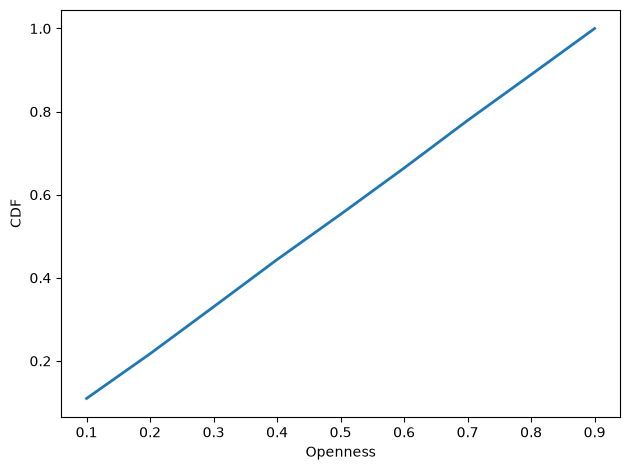

In [93]:
grid = Schelling(n=100, p=0.4)
# Check the initial distribution of openness
cdf = Cdf.from_seq(
    person.openness
    for person in grid.people.values()
)

cdf.plot()

decorate(
    xlabel='Openness',
    ylabel='CDF'
)

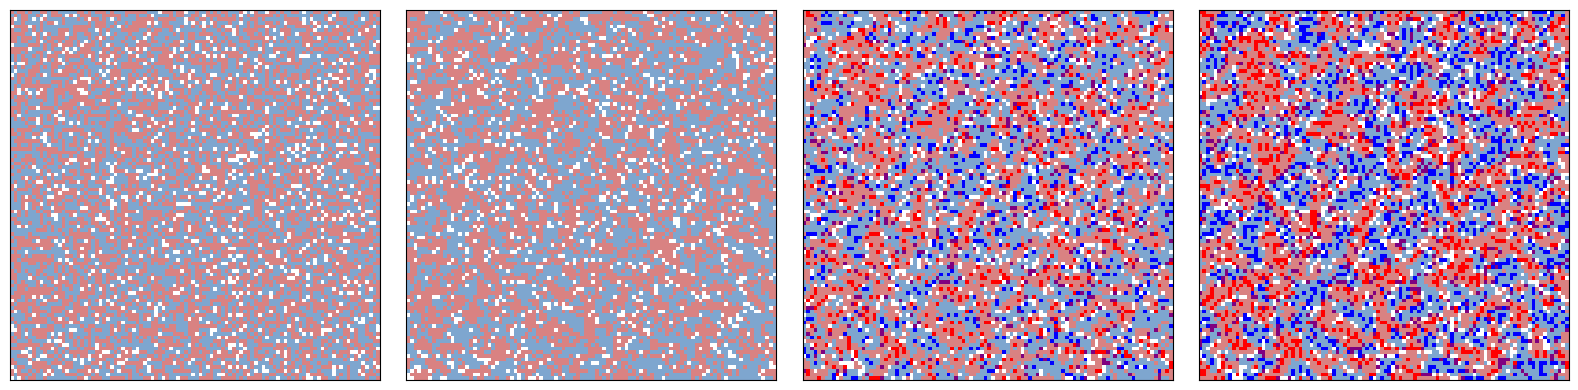

In [107]:
grid = Schelling(n=100, p=0.7, m=0.3)
# three_frame(grid, [0, 2, 8]) #step0,0+2,0+2+8
number_frame(grid,[0,2,3,5],4)

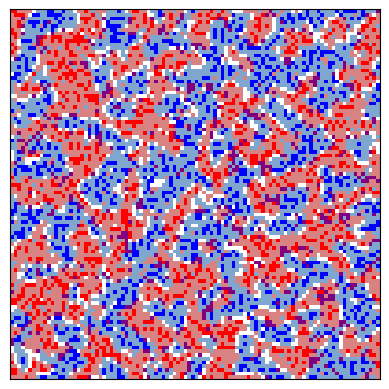

In [108]:
grid.animate(frames=50, interval=0.1) #animate这个function里面有step会自己跳动

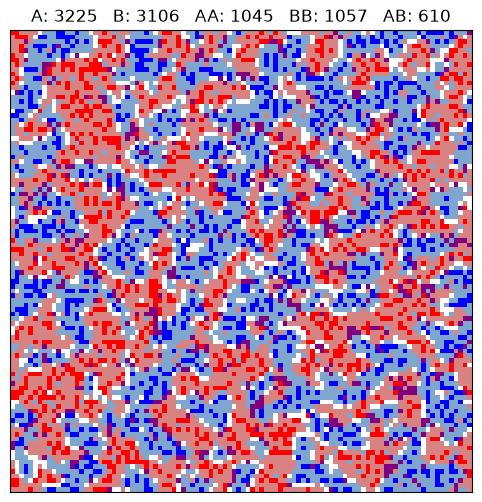

In [110]:
count_a = np.sum(grid.array == 1)
count_b = np.sum(grid.array == 2)
count_aa = np.sum(grid.array == 3)
count_bb = np.sum(grid.array == 4)
count_ab = np.sum(grid.array == 5)

plt.figure(figsize=(6, 6))
grid.draw()
plt.title(
    f"A: {count_a}   B: {count_b}   AA: {count_aa}   "
    f"BB: {count_bb}   AB: {count_ab}"
)
plt.show()

# 图 1：p=0.2 ～ 0.9的整体趋势
这张图主要用来观察不同满意度阈值p对segregation的整体影响。可以看到，p从0.2增加到0.8时，最终segregation总体上逐渐提高；但当p=0.9时，segregation反而下降，而且曲线持续波动。这说明segregation并不是随着p无限增加，而是在较高p附近达到峰值后开始下降。一个可能原因是，当满意度要求过高时，大量Agent很难找到满足条件的位置，因此不断随机搬家，系统反而难以稳定。

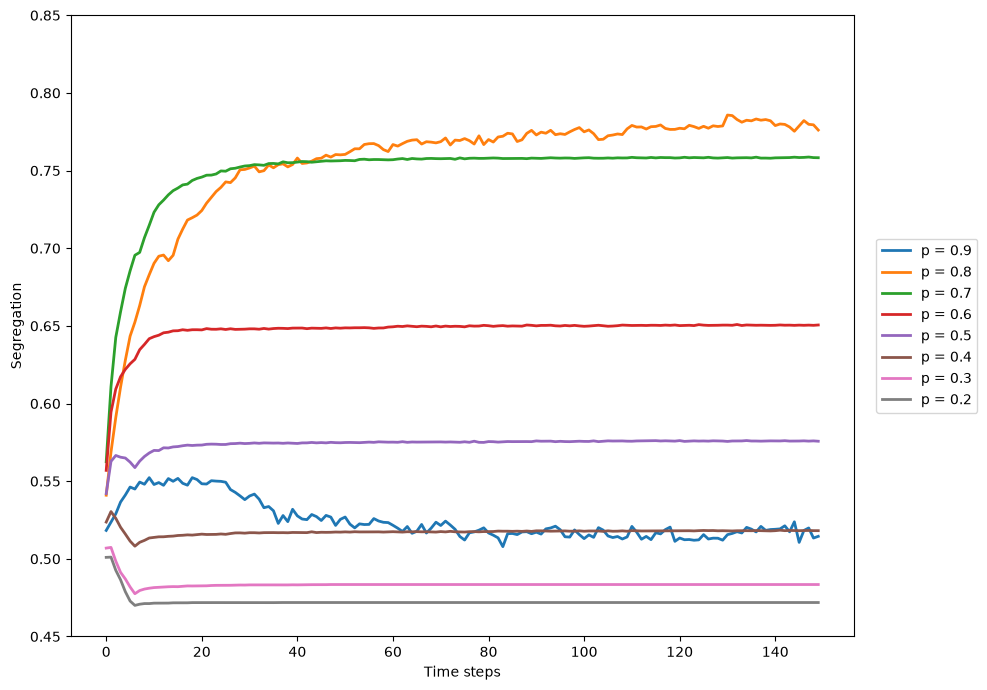

In [97]:
plt.figure(figsize=(10, 7))

for i, p in enumerate([0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2]):

    np.random.seed(17)

    grid = Schelling(n=100, p=p)

    segs = [grid.step() for step in range(150)]

    plt.plot(
        segs,
        label='p = %.1f' % p
    )

decorate(
    xlabel='Time steps',
    ylabel='Segregation', #Segregation 表示一个 Agent 周围的已占用邻居中，有多少比例和自己属于同一个 group，然后再对所有 Agent 取平均。
    ylim=[0.45, 0.85]
)

# 把 legend 放到图的右边外面
plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.tight_layout()
plt.show()

# 图 2：p=0.2 ～ 0.7的稳定速度
这张图主要用来看模型大约需要多少timestep才能稳定。低p情况，例如p=0.2 ～ 0.4，几乎马上稳定，因为大多数Agent一开始已经满足要求。随着p增加，模型需要更多timestep才能稳定，例如 \(p=0.6\) 和 \(p=0.7\) 大约需要15–30个timestep。总体上说明：在正常范围内，满意度要求越高，系统达到稳定状态所需要的时间越长。

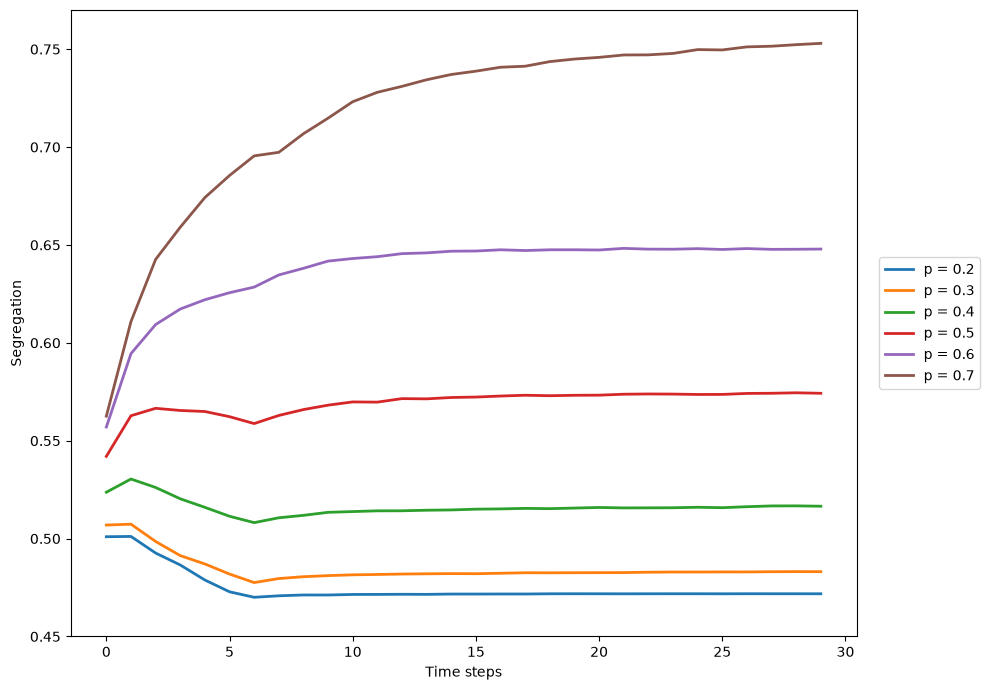

In [98]:
plt.figure(figsize=(10, 7))

for p in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:

    np.random.seed(17)

    grid = Schelling(n=100, p=p)

    segs = [grid.step() for step in range(30)]

    plt.plot(segs, label='p = %.1f' % p)

plt.xlabel('Time steps')
plt.ylabel('Segregation')
plt.ylim(0.45, 0.77)

plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.tight_layout()
plt.show()

# 图 3：p=0.7 ～ 0.9的高满意度区域
这张图把高p区域进一步放大。可以看到p=0.7到0.8时segregation较高，而且最后能够接近稳定；但是从大约p=0.85开始，最终segregation明显下降，同时曲线波动增加。到p=0.9时这种现象最明显。因此，高满意度要求并不一定导致更严重的segregation，反而可能使Agent长时间持续移动，导致系统难以达到equilibrium。

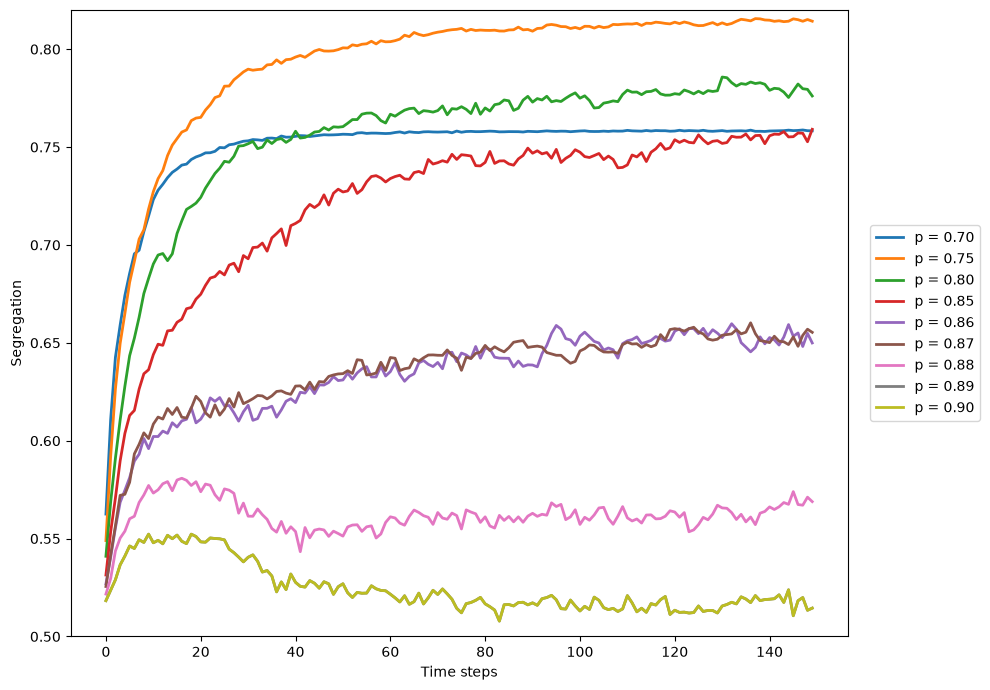

In [99]:
plt.figure(figsize=(10, 7))

for p in [0.7, 0.75, 0.8, 0.85, 0.86, 0.87, 0.88, 0.89, 0.9]:

    np.random.seed(17)

    grid = Schelling(n=100, p=p)

    segs = [grid.step() for step in range(150)]

    plt.plot(segs, label='p = %.2f' % p)

plt.xlabel('Time steps')
plt.ylabel('Segregation')
plt.ylim(0.50, 0.82)

plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.tight_layout()
plt.show()

# 图 4：p=0.75 ～ 0.80的峰值搜索
目前可以认为，在当前模型参数下，segregation的峰值区域大约位于p=0.76 ～ 0.77。这只是当前实验得到的数值峰值，之后还可以增加random seeds来确认它是否稳定。

p = 0.75, mean segregation = 0.8129
p = 0.76, mean segregation = 0.8222
p = 0.77, mean segregation = 0.8202
p = 0.78, mean segregation = 0.7999
p = 0.79, mean segregation = 0.8012
p = 0.80, mean segregation = 0.7883

Peak p = 0.76
Maximum segregation = 0.8221945208440674


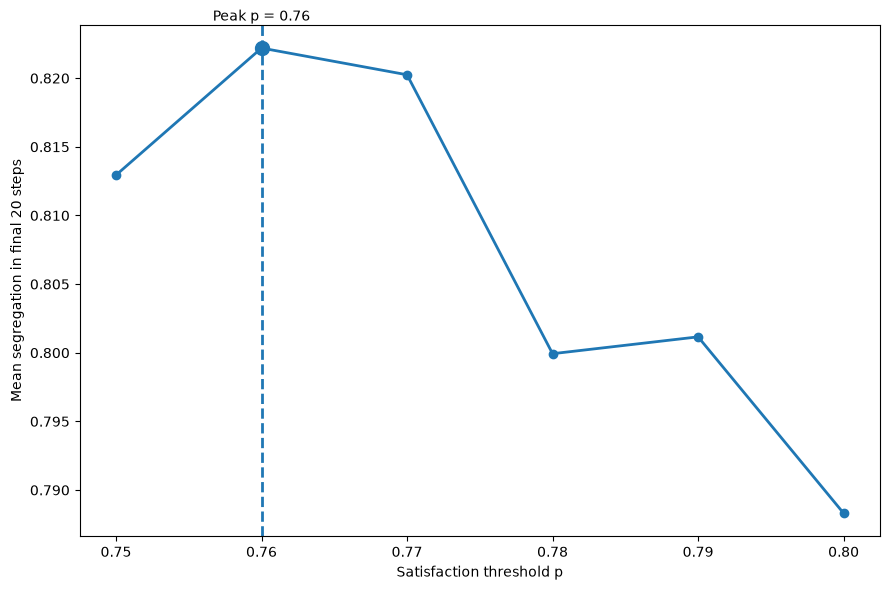

In [100]:
# Test p from 0.75 to 0.80
p_values = np.round(np.arange(0.75, 0.801, 0.01), 2)

seeds = range(5)
n_steps = 200
final_window = 20

mean_segs = []

for p in p_values:

    results = []

    for seed in seeds:

        np.random.seed(seed)

        grid = Schelling(n=100, p=p)

        segs = []

        for step in range(n_steps):
            grid.step()
            segs.append(grid.segregation())

        # Average segregation of the final 20 steps
        results.append(np.mean(segs[-final_window:]))

    # Average result from all seeds
    mean_segs.append(np.mean(results))

    print(f"p = {p:.2f}, "f"mean segregation = {np.mean(results):.4f}")

# Find the maximum
peak_index = np.argmax(mean_segs)

peak_p = p_values[peak_index]
peak_seg = mean_segs[peak_index]

print("\nPeak p =", peak_p)
print("Maximum segregation =", peak_seg)

# Plot
plt.figure(figsize=(9, 6))

plt.plot(p_values, mean_segs, marker='o', linewidth=2)

# Mark the peak
plt.scatter(peak_p, peak_seg, s=100)

plt.axvline(peak_p, linestyle='--')

plt.text(peak_p, peak_seg + 0.002, f'Peak p = {peak_p:.2f}', ha='center')

plt.xlabel('Satisfaction threshold p')
plt.ylabel('Mean segregation in final 20 steps')

plt.xticks(p_values)

plt.tight_layout()
plt.show()